Project Idea

This project aims to predict the species of an iris flower using its sepal length, sepal width, petal length, and petal width. The model will use these measurements to classify the flower into one of three species: Setosa, Versicolor, or Virginica.

This project demonstrates how machine learning can identify patterns in data and make predictions. It uses two classification algorithms, Decision Tree and K-Nearest Neighbors (KNN), to compare their performance.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix


In [2]:

iris = load_iris(as_frame=True)

df = iris.frame

print("First five rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()


First five rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 no

In [3]:

print("Missing values in each column:")
print(df.isnull().sum())

if df.isnull().sum().sum() == 0:
    print("\nThere are no missing values in the dataset.")
else:
    print("\nThe dataset contains missing values.")


Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

There are no missing values in the dataset.


In [4]:

X = iris.data

y = iris.target

print("Feature columns:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nSpecies names:")
print(iris.target_names)


Feature columns:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target values:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Species names:
['setosa' 'versicolor' 'virginica']


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Total samples: 150
Training samples: 120
Testing samples: 30


In [6]:

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree predictions:")
print(dt_predictions)

print("\nActual species:")
print(y_test.to_numpy())


Decision Tree predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Actual species:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [7]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

print("KNN predictions:")
print(knn_predictions)

print("\nActual species:")
print(y_test.to_numpy())


KNN predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]

Actual species:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [8]:

dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy (%)": [
        round(dt_accuracy * 100, 2),
        round(knn_accuracy * 100, 2)
    ]
})

print("\nModel Comparison:")
print(results.to_string(index=False))


Decision Tree Accuracy: 93.33 %
KNN Accuracy: 93.33 %

Model Comparison:
        Model  Accuracy (%)
Decision Tree         93.33
          KNN         93.33


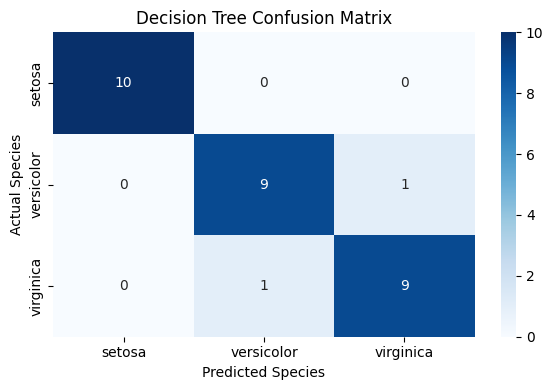

In [9]:

dt_cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()


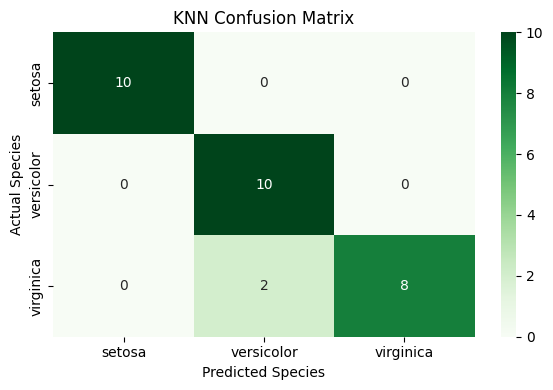

In [10]:

knn_cm = confusion_matrix(y_test, knn_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()


In [11]:

if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better on this test set.")
elif knn_accuracy > dt_accuracy:
    print("KNN performed better on this test set.")
else:
    print("Both models achieved the same accuracy on this test set.")

print("\nFinal Results:")
print(results.to_string(index=False))


Both models achieved the same accuracy on this test set.

Final Results:
        Model  Accuracy (%)
Decision Tree         93.33
          KNN         93.33


In this project, I developed two machine learning models,
Decision Tree and K-Nearest Neighbors (KNN), to classify
iris flowers using their measurements.

The dataset was checked for missing values, and the
features and target were separated before training.
The dataset was then divided into training and testing sets.